# Visualisation 3D d'une main

Test du squelette articulaire et de la surface MANO avec un item de Text2HOI.

In [11]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import torch
from IPython.display import HTML, display

PROJECT_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "data" / "text2hoi_loader.py").is_file()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from data import Mano3DPlot, get_Text2HOI_loader

try:
    import ipympl
    get_ipython().run_line_magic("matplotlib", "widget")
    INTERACTIVE_3D = True
except ImportError:
    get_ipython().run_line_magic("matplotlib", "inline")
    INTERACTIVE_3D = False
    print("Installer ipympl pour manipuler la vue 3D avec la souris.")

In [12]:
DATASET_NAME = "h2O"
BATCH_SIZE = 8
MAX_FRAMES = 150
SAMPLE_ID = 5

torch.manual_seed(0)
loader = get_Text2HOI_loader(
    dataset_name=DATASET_NAME,
    batch_size=BATCH_SIZE,
    shuffle=True,
    max_frames=MAX_FRAMES,
    train=False,
    use_paraphrases=False,
)
batch = next(iter(loader))

for index, text in enumerate(batch["text"]):
    hands = []
    if bool(batch["is_lhand"][index]):
        hands.append("gauche")
    if bool(batch["is_rhand"][index]):
        hands.append("droite")
    print(index, " + ".join(hands), text)

0 gauche + droite Put in cappuccino with both hands.
1 droite Squeeze lotion with right hand.
2 droite Place spray with right hand.
3 gauche + droite Take out chips with both hands.
4 gauche + droite Open lotion with both hands.
5 gauche Place cappuccino with left hand.
6 gauche + droite Place lotion with both hands.
7 gauche + droite Place lotion with both hands.


In [13]:
frame_count = int(batch["frame_mask"][SAMPLE_ID].sum())
has_left = bool(batch["is_lhand"][SAMPLE_ID])
has_right = bool(batch["is_rhand"][SAMPLE_ID])
left_joints = batch["j_lhand"][SAMPLE_ID, :frame_count] if has_left else None
right_joints = batch["j_rhand"][SAMPLE_ID, :frame_count] if has_right else None
left_parameters = batch["x_lhand"][SAMPLE_ID, :frame_count] if has_left else None
right_parameters = batch["x_rhand"][SAMPLE_ID, :frame_count] if has_right else None
left_betas = batch["lhand_beta"][SAMPLE_ID, :frame_count] if has_left else None
right_betas = batch["rhand_beta"][SAMPLE_ID, :frame_count] if has_right else None
title = batch["text"][SAMPLE_ID]

print(title)
print("main gauche:", has_left)
print("main droite:", has_right)
print(frame_count, "frames")

Place cappuccino with left hand.
main gauche: True
main droite: False
50 frames


## Articulations XYZ

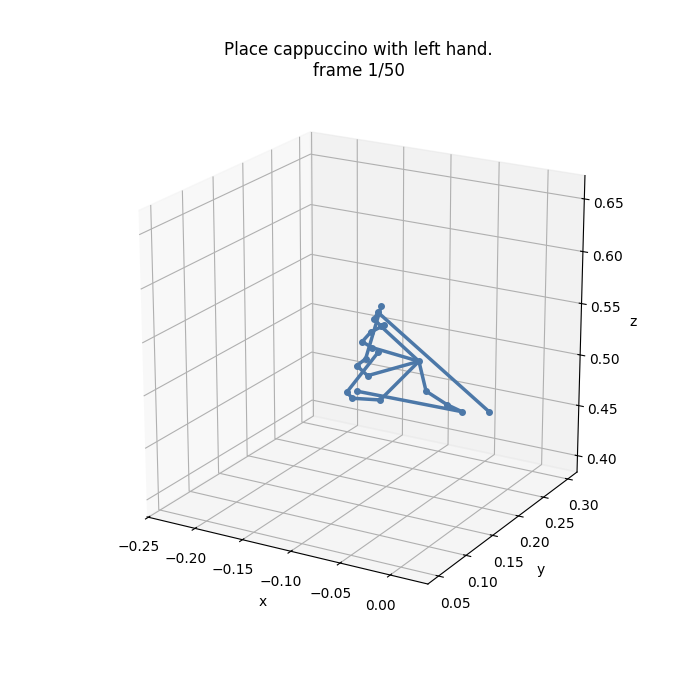

In [14]:
visualizer = Mano3DPlot(fps=20)
joint_animation = visualizer.animate_hands(
    left_joints=left_joints,
    right_joints=right_joints,
    title=title,
)
if INTERACTIVE_3D:
    plt.show()
else:
    plt.close(joint_animation._fig)
    display(HTML(joint_animation.to_jshtml(fps=visualizer.fps)))

## Surface MANO

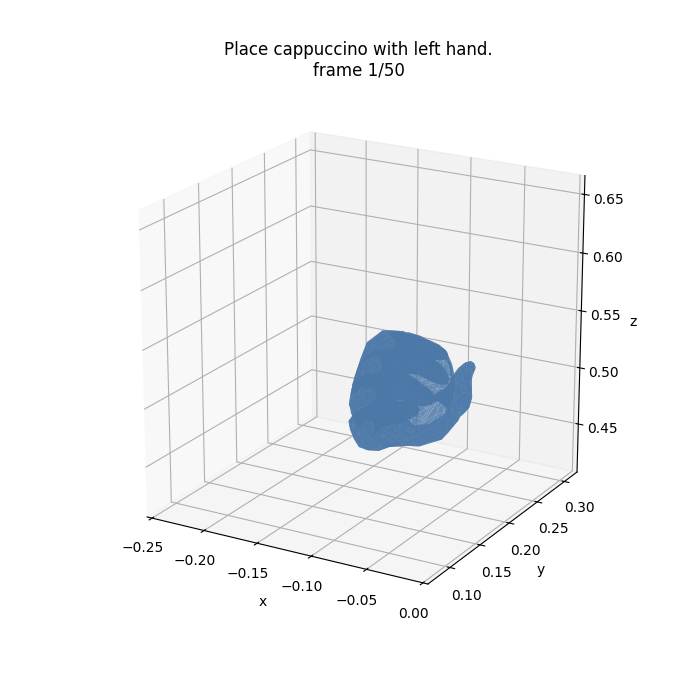

In [15]:
mano_animation = visualizer.animate_mano_hands(
    left_parameters=left_parameters,
    left_betas=left_betas,
    right_parameters=right_parameters,
    right_betas=right_betas,
    left_joints=left_joints,
    right_joints=right_joints,
    show_joints=False,
    title=title,
)
if INTERACTIVE_3D:
    plt.show()
else:
    plt.close(mano_animation._fig)
    display(HTML(mano_animation.to_jshtml(fps=visualizer.fps)))